# Zyla + PCI-6259 acquisition
In Solis, select External Start Trigger and arm/start the camera before running the acquisition cell.

In [1]:
from pathlib import Path
from acquire_zyla_ni import AcquisitionConfig, run_acquisition

ModuleNotFoundError: No module named 'acquire_zyla_ni'

In [ ]:
# Phantom TMX
config = AcquisitionConfig(
    sample_rate_hz=100_000,
    duration_s=2.0,
    trigger_delay_s=0.100,
    trigger_high_s=0.001,
    trigger_active_low=True, # False if Andor Zyla, True if TMX Phantom
)
output = run_acquisition(
    Path(r"data") / "phantom_test_13.npz",
    config
)
print(f'Saved: {output}')

Saved: D:\Code\zyla_ni_acquisition\data\phantom_test_13.npz


In [121]:
# For Phantom TMX

config = AcquisitionConfig(
    sample_rate_hz=500_000,
    duration_s=4.0,

    trigger_delay_s=0.100,
    trigger_high_s=0.001,
    trigger_active_low=True,

    camera_min_v=-10.0,
    camera_max_v=10.0,

    photodiode_min_v=-0.1,
    photodiode_max_v=0.3,
)

output = run_acquisition(
    Path(r"data") / "phantom_test_particles_3.npz",
    config
)
print(f'Saved: {output}')

Saved: D:\Code\zyla_ni_acquisition\data\phantom_test_particles_3.npz


In [122]:
import json
import numpy as np
run = np.load(output, allow_pickle=False)
print(run.files)
print(json.loads(str(run['metadata_json'])))

['camera_frame_signal', 'photodiode_signal', 'time_s', 'metadata_json']
{'device': 'Dev1', 'camera_channel': 'Dev1/ai2', 'photodiode_channel': 'Dev1/ai0', 'trigger_line': 'Dev1/port0/line0', 'sample_rate_hz': 500000, 'duration_s': 4.0, 'trigger_delay_s': 0.1, 'trigger_high_s': 0.001, 'trigger_active_low': True, 'camera_min_v': -10.0, 'camera_max_v': 10.0, 'photodiode_min_v': -0.1, 'photodiode_max_v': 0.3, 'read_chunk_s': 0.05, 'samples_acquired_per_channel': 2000000, 'acquisition_start_monotonic_ns': 89560068970100, 'trigger_command_monotonic_ns': 89560169113900, 'trigger_complete_monotonic_ns': 89560171300800, 'trigger_time_from_acquisition_start_s': 0.1001438, 'trigger_timing_note': 'Software-timed NI digital write; timestamp includes host scheduling uncertainty.'}


In [2]:
import numpy as np
import matplotlib.pyplot as plt

file  = np.load(r'/Volumes/Extreme SSD/Masterarbeit/APD/220926/HeLa/100_50_BF.npz')

print("Contents:", file.files)

for key in file.files:
    arr = file[key]
    print(f"{key}: shape={arr.shape}, dtype={arr.dtype}")

Contents: ['camera_frame_signal', 'photodiode_signal', 'time_s', 'metadata_json']
camera_frame_signal: shape=(15000000,), dtype=float64
photodiode_signal: shape=(15000000,), dtype=float64
time_s: shape=(15000000,), dtype=float64
metadata_json: shape=(), dtype=<U755


In [3]:
print("Maximale Zeit:", file["time_s"].max(), "s")

Maximale Zeit: 29.999998 s


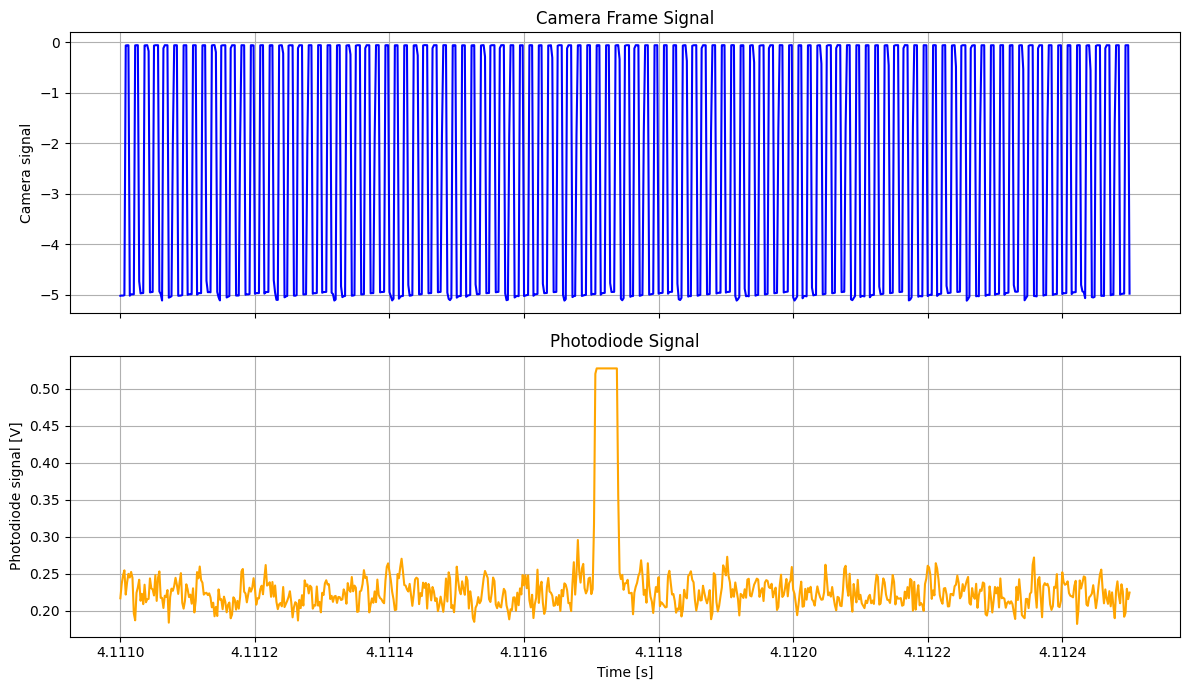

In [9]:
t = file["time_s"]
camera = file["camera_frame_signal"]
photodiode = file["photodiode_signal"]

# Zeitbereich auswählen
t_min = 4.111
t_max = 4.1125

mask = (t >= t_min) & (t <= t_max)

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Camera frame signal
ax[0].plot(t[mask], camera[mask], color="blue")
ax[0].set_ylabel("Camera signal")
ax[0].set_title("Camera Frame Signal")
ax[0].grid()

# Photodiode signal
ax[1].plot(t[mask], photodiode[mask], color="orange")
ax[1].set_xlabel("Time [s]")
ax[1].set_ylabel("Photodiode signal [V]")
ax[1].set_title("Photodiode Signal")
ax[1].grid()

plt.tight_layout()
plt.show()